# Punto 4 (0.6) — YIQ: gamma sobre Y y Q por -1

Aplique la transformación a su imagen RGB.

- Paso 1. Convierta su imagen RGB al espacio YIQ
- Paso 2. Aplique una transformación Gamma al componente de Luminancia con γ=1.5
- Paso 3. Transforme el componente Q multiplicándolo por -1
- Paso 4. Reconstruya la imagen YIQ con el componente de luminancia transformado en el paso 2, el componente Q transformado en el paso 3 y los demás componentes sin modificar
- Paso 5. Convierta la imagen obtenida en el Paso 4 al espacio RGB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from skimage.color import rgb2yiq, yiq2rgb


## Imagen original RGB

(1024, 1024, 3) uint8


(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

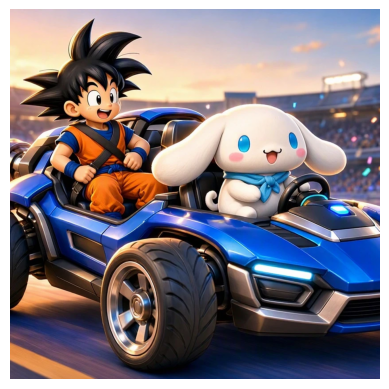

In [2]:
img = np.array(Image.open("../images/mi_imagen.png").convert("RGB"))
print(img.shape, img.dtype)

plt.figure()
plt.imshow(img)
plt.axis("off")


## Paso 1 — RGB a YIQ

In [3]:
yiq = rgb2yiq(img)
print(yiq.min(axis=(0, 1)).round(3), yiq.max(axis=(0, 1)).round(3))


[ 0.    -0.526 -0.179] [1.    0.469 0.173]


## Paso 2 — Gamma (γ=1.5) sobre Y

In [4]:
y = np.round(np.clip(yiq[..., 0], 0, 1) * 255).astype(np.uint8)

y_gamma = np.zeros_like(y)
cv2.intensity_transform.gammaCorrection(y, y_gamma, 1.5)


## Paso 3 — Q por -1

In [5]:
q_mod = -yiq[..., 2]


## Pasos 4 y 5 — Reconstrucción y vuelta a RGB

In [6]:
yiq_mod = yiq.copy()
yiq_mod[..., 0] = y_gamma / 255.0
yiq_mod[..., 2] = q_mod
resultado = np.clip(np.round(yiq2rgb(yiq_mod) * 255), 0, 255).astype(np.uint8)

Image.fromarray(resultado).save("../results/punto4_transformada.png")


## Comparación original vs transformada

Complete la tabla con la imagen original RGB y la imagen transformada.

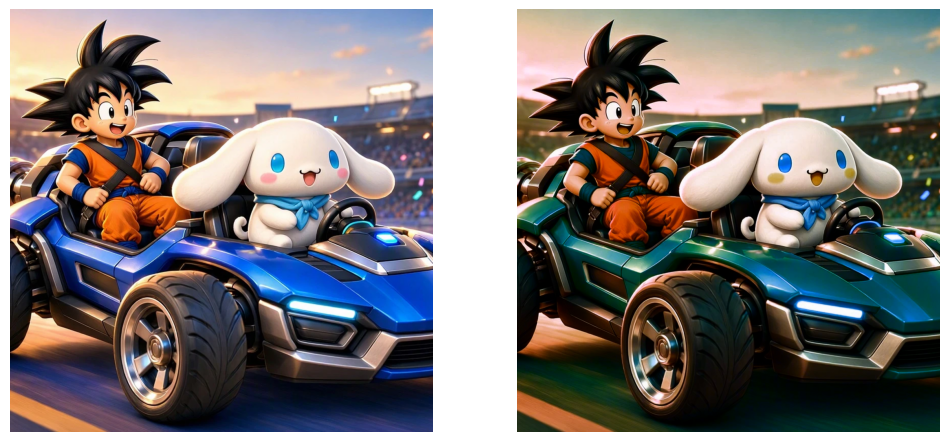

In [7]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(resultado)
plt.axis("off")
plt.savefig("../results/punto4_comparacion.png", bbox_inches="tight", pad_inches=0)
